In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [25]:
df = pd.read_csv("Churn_Modelling_Messy_Practice.csv")
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619.0,France,Female,42.0,2.0,0.00,1.0,1.0,1.0,101348.88,1
1,2,15647311,Hill,608.0,Spain,Female,41.0,1.0,83807.86,1.0,0.0,1.0,112542.58,0
2,3,15619304,Onio,502.0,France,Female,42.0,8.0,159660.80,3.0,1.0,0.0,113931.57,1
3,4,15701354,Boni,699.0,France,Female,39.0,1.0,0.00,2.0,0.0,0.0,93826.63,0
4,5,15737888,Mitchell,850.0,Spain,Female,43.0,2.0,125510.82,1.0,1.0,1.0,79084.10,0


In [26]:
df.shape

(10100, 14)

In [5]:
df.isnull().sum()

RowNumber            0
CustomerId           0
Surname            101
CreditScore        151
Geography          150
Gender             101
Age                102
Tenure             101
Balance            201
NumOfProducts      100
HasCrCard           51
IsActiveMember     101
EstimatedSalary    201
Exited               0
dtype: int64

In [6]:
features_with_na = [features for features in df.columns if df[features].isnull().sum() >= 1]

for feature in features_with_na:
    print(feature, np.round(df[feature].isnull().mean() * 100, 2), '% missing values')

Surname 1.0 % missing values
CreditScore 1.5 % missing values
Geography 1.49 % missing values
Gender 1.0 % missing values
Age 1.01 % missing values
Tenure 1.0 % missing values
Balance 1.99 % missing values
NumOfProducts 0.99 % missing values
HasCrCard 0.5 % missing values
IsActiveMember 1.0 % missing values
EstimatedSalary 1.99 % missing values


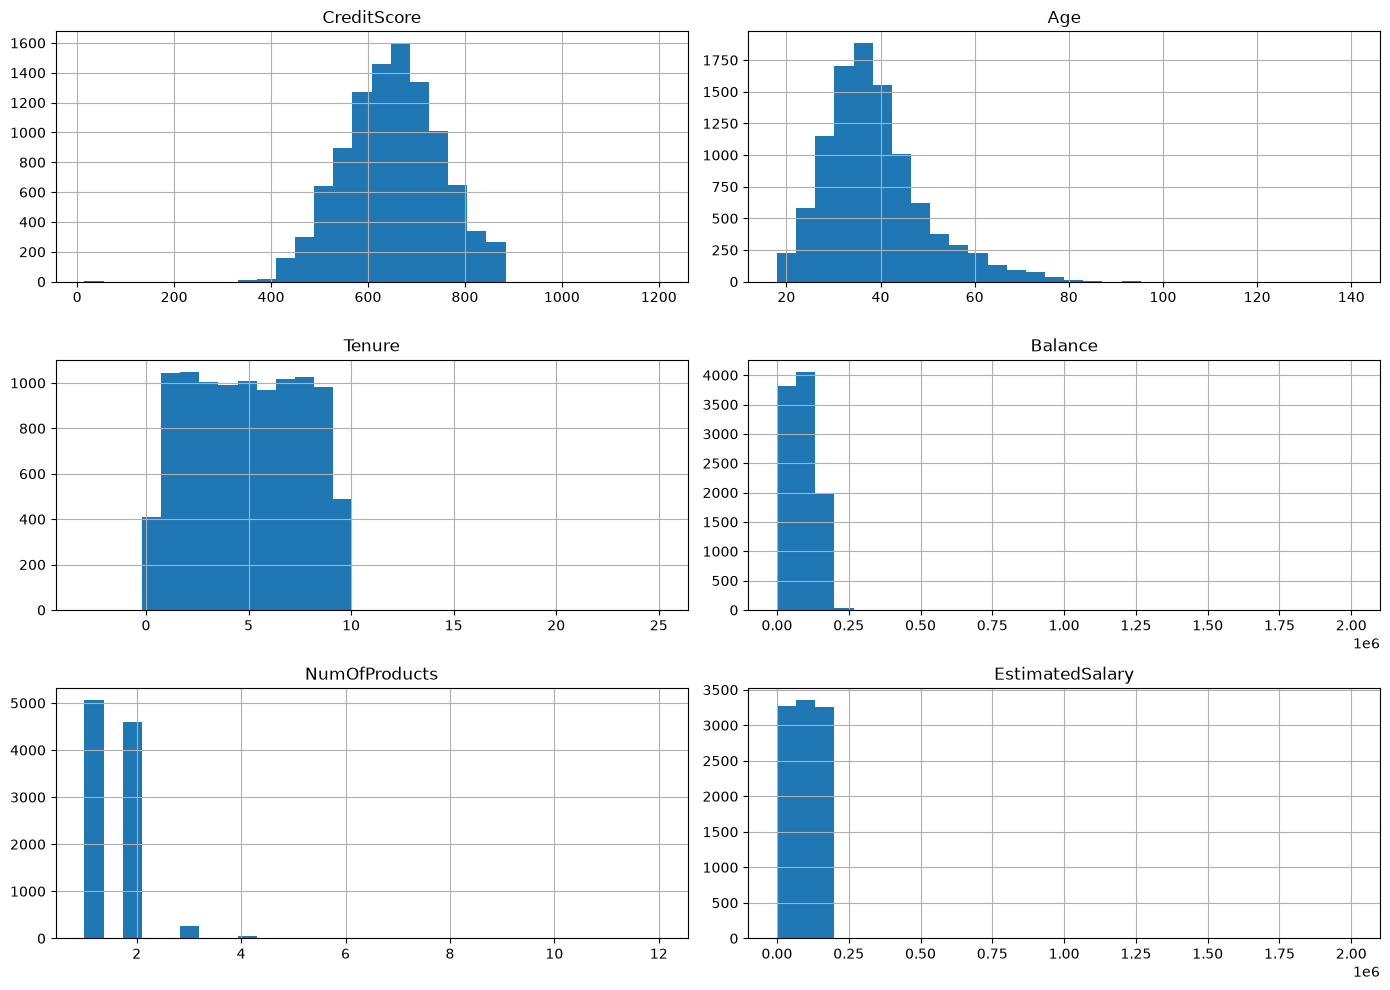

In [7]:
numerical_features = ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'EstimatedSalary']

df[numerical_features].hist(figsize=(14, 10), bins=30)
plt.tight_layout()
plt.show()

In [ ]:
df['CreditScore'] = df['CreditScore'].fillna(df['CreditScore'].mean())
df['Tenure'] = df['Tenure'].fillna(df['Tenure'].mean())

df['EstimatedSalary'] = df['EstimatedSalary'].fillna(df['EstimatedSalary'].median())
df['Age'] = df['Age'].fillna(df['Age'].median())
df['Balance'] = df['Balance'].fillna(df['Balance'].median())
df['NumOfProducts'] = df['NumOfProducts'].fillna(df['NumOfProducts'].median())

df[numerical_features].isnull().sum()

CreditScore        0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
EstimatedSalary    0
dtype: int64

In [11]:
categorical_features = ['Geography', 'Gender']

for feature in categorical_features:
    mode_value = df[feature].mode()[0]
    df[feature] = df[feature].fillna(mode_value)

df['Surname'] = df['Surname'].fillna(df['Surname'].mode()[0])
df['HasCrCard'] = df['HasCrCard'].fillna(df['HasCrCard'].mode()[0])
df['IsActiveMember'] = df['IsActiveMember'].fillna(df['IsActiveMember'].mode()[0])

df.isnull().sum()

RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

In [12]:
print("Exact duplicate rows:", df.duplicated().sum())

Exact duplicate rows: 100


In [13]:
duplicate_rows = df.duplicated().sum()
df = df.drop_duplicates()

print("Rows removed:", duplicate_rows)
print("Shape after removing duplicates:", df.shape)

Rows removed: 100
Shape after removing duplicates: (10000, 14)


## Remove Trailing Spaces

In [28]:
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619.0,France,Female,42.0,2.0,0.00,1.0,1.0,1.0,101348.88,1
1,2,15647311,Hill,608.0,Spain,Female,41.0,1.0,83807.86,1.0,0.0,1.0,112542.58,0
2,3,15619304,Onio,502.0,France,Female,42.0,8.0,159660.80,3.0,1.0,0.0,113931.57,1
3,4,15701354,Boni,699.0,France,Female,39.0,1.0,0.00,2.0,0.0,0.0,93826.63,0
4,5,15737888,Mitchell,850.0,Spain,Female,43.0,2.0,125510.82,1.0,1.0,1.0,79084.10,0


In [15]:
df['Geography'] = df['Geography'].str.strip().str.title()
df['Gender'] = df['Gender'].str.strip().str.title()
df['Surname'] = df['Surname'].str.strip()


## Handling Outliers

In [16]:
num_features = df.select_dtypes(include='number').drop(
    columns=['RowNumber', 'CustomerId', 'Exited', 'HasCrCard', 'IsActiveMember'],
    errors='ignore'
)

Q1 = num_features.quantile(0.25)
Q3 = num_features.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = (num_features < lower_bound) | (num_features > upper_bound)

print("Outlier count for each numerical feature:")
print(outliers.sum())

Outlier count for each numerical feature:
CreditScore         22
Age                362
Tenure               4
Balance              5
NumOfProducts       63
EstimatedSalary      5
dtype: int64


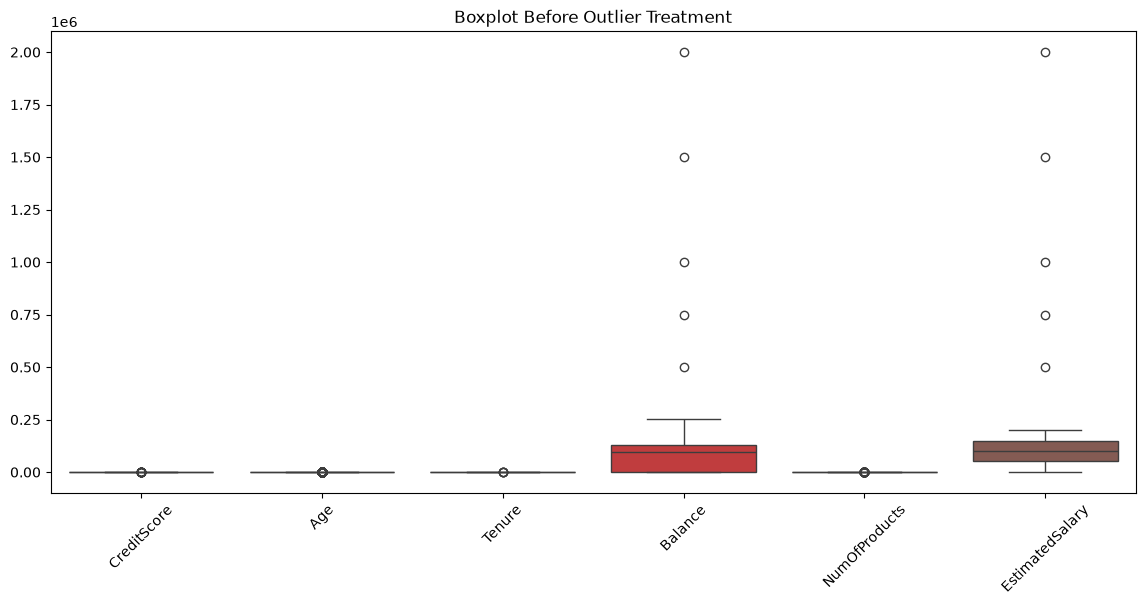

In [17]:
plt.figure(figsize=(14, 6))
sns.boxplot(data=num_features)
plt.xticks(rotation=45)
plt.title("Boxplot Before Outlier Treatment")
plt.show()

## Handling Outliers using IQR Capping

In [ ]:
for feature in num_features.columns:

    Q1 = num_features[feature].quantile(0.25)
    Q3 = num_features[feature].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    df[feature] = np.where(df[feature] < lower_bound, lower_bound,
                  np.where(df[feature] > upper_bound, upper_bound, df[feature]))

print("Outliers handled successfully!")

Outliers handled successfully!


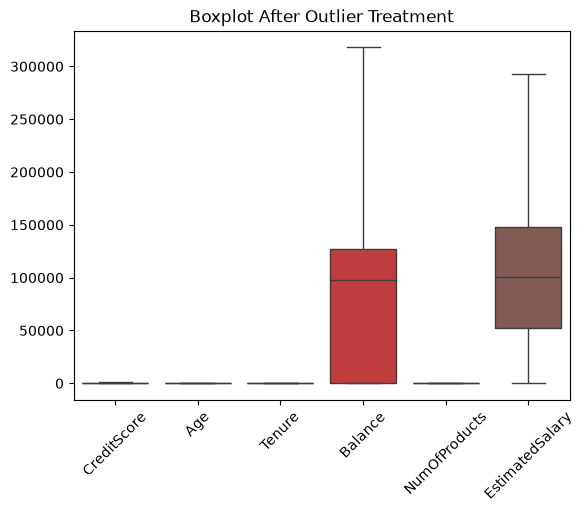

In [22]:
sns.boxplot(data=df[num_features.columns])
plt.xticks(rotation=45)
plt.title("Boxplot After Outlier Treatment")
plt.show()

In [19]:
print("Missing values in cleaned dataframe:", df.isnull().sum().sum())
print("Duplicate rows in cleaned dataframe:", df.duplicated().sum())

Missing values in cleaned dataframe: 0
Duplicate rows in cleaned dataframe: 0


In [24]:
df.to_csv("cleaned_customer_churn.csv", index=False)